In [1]:
import os
import subprocess

# Configure Java 17
JAVA_HOME = os.path.expanduser("~/java17-env")

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["PATH"] = JAVA_HOME + "/bin:" + os.environ["PATH"]

# Limit Java's detected CPU count
os.environ["JAVA_TOOL_OPTIONS"] = "-XX:ActiveProcessorCount=2"

print("Java version:")
print(subprocess.getoutput("java -version 2>&1"))

print("\nPySpark version:")
import pyspark
print(pyspark.__version__)

Java version:
Picked up JAVA_TOOL_OPTIONS: -XX:ActiveProcessorCount=2
openjdk version "17.0.18-internal" 2026-01-20
OpenJDK Runtime Environment (build 17.0.18-internal+0-adhoc.rattler.src)
OpenJDK 64-Bit Server VM (build 17.0.18-internal+0-adhoc.rattler.src, mixed mode, sharing)

PySpark version:
3.5.6


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[1]")
    .appName("PerfectPetClub_ML")
    .config("spark.driver.memory", "2g")
    .config("spark.default.parallelism", "1")
    .config("spark.sql.shuffle.partitions", "2")
    .config("spark.driver.host", "127.0.0.1")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

Picked up JAVA_TOOL_OPTIONS: -XX:ActiveProcessorCount=2
Picked up JAVA_TOOL_OPTIONS: -XX:ActiveProcessorCount=2
26/11/15 17:59:26 WARN Utils: Your hostname, green-nbjupyterhub25 resolves to a loopback address: 127.0.0.1; using 10.0.0.165 instead (on interface ens5)
26/11/15 17:59:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 17:59:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.6
Spark master: local[1]


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
parquet_path = str(PROJECT_DIR / "data" / "processed" / "perfectpetclub_processed.parquet")

df = spark.read.parquet(parquet_path)

print("Total rows:", df.count())
print("Total columns:", len(df.columns))

df.printSchema()

Total rows: 221
Total columns: 34
root
 |-- total_orders: long (nullable = true)
 |-- total_spend: long (nullable = true)
 |-- average_order_value: double (nullable = true)
 |-- total_items: long (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- total_reviews: double (nullable = true)
 |-- total_crm_interactions: double (nullable = true)
 |-- total_logins: long (nullable = true)
 |-- subscription_type_id: long (nullable = true)
 |-- nps_recommend: long (nullable = true)
 |-- satisfaction_score: long (nullable = true)
 |-- online_comparison_freq: long (nullable = true)
 |-- churn: long (nullable = true)
 |-- days_since_last_order: long (nullable = true)
 |-- reported_income_146k-150k: long (nullable = true)
 |-- reported_income_150k-154k: long (nullable = true)
 |-- reported_income_18k-22k: long (nullable = true)
 |-- reported_income_198k-200k+: long (nullable = true)
 |-- reported_income_22k-26k: long (nullable = true)
 |-- reported_income_26k-30k: long (nullable = t

In [4]:
df.groupBy("churn").count().orderBy("churn").show()

+-----+-----+
|churn|count|
+-----+-----+
|    0|  135|
|    1|   86|
+-----+-----+



In [5]:
from pyspark.ml.feature import VectorAssembler

# Separate input features and target
feature_cols = [c for c in df.columns if c != "churn"]

# Convert input columns into a single feature vector
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

data = assembler.transform(df).select("features", "churn")

# Split dataset
train_df, test_df = data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())
print("Number of features:", len(feature_cols))

Training records: 187
Testing records: 34
Number of features: 33


In [6]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=10,
    regParam=0.1
)

lr_model = lr.fit(train_df)

print("Logistic Regression training completed!")

[143.569s][warning][os,thread] Failed to start thread "Unknown thread" - pthread_create failed (EAGAIN) for attributes: stacksize: 1024k, guardsize: 0k, detached.
[143.569s][warning][os,thread] Failed to start the native thread for java.lang.Thread "block-manager-storage-async-thread-pool-88"
[143.596s][warning][os,thread] Failed to start thread "Unknown thread" - pthread_create failed (EAGAIN) for attributes: stacksize: 1024k, guardsize: 0k, detached.
[143.596s][warning][os,thread] Failed to start the native thread for java.lang.Thread "block-manager-storage-async-thread-pool-89"
[143.596s][warning][os,thread] Failed to start thread "Unknown thread" - pthread_create failed (EAGAIN) for attributes: stacksize: 1024k, guardsize: 0k, detached.
[143.596s][warning][os,thread] Failed to start the native thread for java.lang.Thread "block-manager-ask-thread-pool-58"
[143.599s][warning][os,thread] Failed to start thread "Unknown thread" - pthread_create failed (EAGAIN) for attributes: stacksiz

java.lang.IllegalStateException: problem in scala.concurrent internal callback
	at scala.concurrent.Future$InternalCallbackExecutor$.reportFailure(Future.scala:877)
	at scala.concurrent.impl.CallbackRunnable.executeWithValue(Promise.scala:72)
	at scala.concurrent.impl.Promise$DefaultPromise.$anonfun$tryComplete$1(Promise.scala:288)
	at scala.concurrent.impl.Promise$DefaultPromise.$anonfun$tryComplete$1$adapted(Promise.scala:288)
	at scala.concurrent.impl.Promise$DefaultPromise.tryComplete(Promise.scala:288)
	at scala.concurrent.Promise.complete(Promise.scala:53)
	at scala.concurrent.Promise.complete$(Promise.scala:52)
	at scala.concurrent.impl.Promise$DefaultPromise.complete(Promise.scala:187)
	at scala.concurrent.impl.Promise.$anonfun$transform$1(Promise.scala:33)
	at scala.concurrent.impl.CallbackRunnable.run(Promise.scala:64)
	at java.base/java.util.concurrent.ThreadPoolExecutor.runWorker(ThreadPoolExecutor.java:1136)
	at java.base/java.util.concurrent.ThreadPoolExecutor$Worker.run(

Logistic Regression training completed!


In [7]:
print("Model exists:", lr_model is not None)

print("Model coefficients:", len(lr_model.coefficients))
print("Model intercept:", lr_model.intercept)

Model exists: True
Model coefficients: 33
Model intercept: -2.5332362453788844


In [8]:
lr_predictions = lr_model.transform(test_df)

lr_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|1    |1.0       |[0.4079636591043924,0.5920363408956075] |
|0    |0.0       |[0.7972490685325995,0.20275093146740053]|
|1    |1.0       |[0.27818717293293366,0.7218128270670663]|
|0    |0.0       |[0.6416813545226743,0.3583186454773257] |
|0    |0.0       |[0.5715971344914825,0.42840286550851747]|
|0    |0.0       |[0.6268696368178953,0.3731303631821047] |
|1    |1.0       |[0.10663726947744125,0.8933627305225588]|
|1    |0.0       |[0.6532510415274757,0.3467489584725243] |
|0    |0.0       |[0.7550665798625941,0.24493342013740593]|
|1    |0.0       |[0.7192010029876705,0.28079899701232947]|
+-----+----------+----------------------------------------+
only showing top 10 rows



In [9]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# Accuracy
accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(lr_predictions)

# Precision
precision = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(lr_predictions)

# Recall
recall = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(lr_predictions)

# F1 Score
f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(lr_predictions)

# ROC-AUC
auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(lr_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy:  0.9118
Precision: 0.9224
Recall:    0.9118
F1 Score:  0.9083
ROC-AUC:   0.9432


In [10]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": auc
}

results = [lr_results]

print("Logistic Regression results saved!")

Logistic Regression results saved!


In [11]:
from pyspark.ml.classification import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="churn",
    maxDepth=5,
    seed=42
)

dt_model = dt.fit(train_df)

print("Decision Tree training completed!")

Decision Tree training completed!


In [12]:
print("Decision Tree model exists:", dt_model is not None)
print("Maximum tree depth:", dt_model.depth)
print("Number of tree nodes:", dt_model.numNodes)

Decision Tree model exists: True
Maximum tree depth: 5
Number of tree nodes: 17


In [13]:
dt_predictions = dt_model.transform(test_df)

dt_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+-----------+
|churn|prediction|probability|
+-----+----------+-----------+
|1    |1.0       |[0.0,1.0]  |
|0    |0.0       |[0.99,0.01]|
|1    |1.0       |[0.0,1.0]  |
|0    |0.0       |[0.99,0.01]|
|0    |0.0       |[0.99,0.01]|
|0    |0.0       |[0.99,0.01]|
|1    |1.0       |[0.0,1.0]  |
|1    |1.0       |[0.0,1.0]  |
|0    |0.0       |[0.99,0.01]|
|1    |1.0       |[0.0,1.0]  |
+-----+----------+-----------+
only showing top 10 rows



In [14]:
accuracy_dt = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(dt_predictions)

precision_dt = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(dt_predictions)

recall_dt = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(dt_predictions)

f1_dt = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(dt_predictions)

auc_dt = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(dt_predictions)

print("DECISION TREE RESULTS")
print("---------------------")
print(f"Accuracy:  {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")
print(f"F1 Score:  {f1_dt:.4f}")
print(f"ROC-AUC:   {auc_dt:.4f}")

DECISION TREE RESULTS
---------------------
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC-AUC:   1.0000


In [15]:
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt,
    "ROC-AUC": auc_dt
}

results.append(dt_results)

print("Decision Tree results saved!")
print("Models completed:", len(results))

Decision Tree results saved!
Models completed: 2


In [16]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=20,
    maxDepth=5,
    seed=42
)

rf_model = rf.fit(train_df)

print("Random Forest training completed!")

Random Forest training completed!


In [17]:
rf_predictions = rf_model.transform(test_df)

rf_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|1    |0.0       |[0.5215611166388049,0.4784388833611951] |
|0    |0.0       |[0.8088715793386902,0.19112842066130975]|
|1    |1.0       |[0.2722236297811268,0.7277763702188731] |
|0    |0.0       |[0.720704911489349,0.2792950885106511]  |
|0    |0.0       |[0.7061443845982902,0.2938556154017097] |
|0    |0.0       |[0.6187123259043702,0.38128767409562986]|
|1    |1.0       |[0.26872151596687577,0.7312784840331242]|
|1    |1.0       |[0.22592988879988582,0.7740701112001142]|
|0    |0.0       |[0.7323219786709809,0.2676780213290191] |
|1    |1.0       |[0.1496239946647555,0.8503760053352444] |
+-----+----------+----------------------------------------+
only showing top 10 rows



In [18]:
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

accuracy_rf = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(rf_predictions)

precision_rf = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(rf_predictions)

recall_rf = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(rf_predictions)

f1_rf = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(rf_predictions)

auc_rf = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_predictions)

print("RANDOM FOREST RESULTS")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1 Score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {auc_rf:.4f}")

RANDOM FOREST RESULTS
Accuracy:  0.9706
Precision: 0.9719
Recall:    0.9706
F1 Score:  0.9703
ROC-AUC:   1.0000


In [19]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1 Score": f1_rf,
    "ROC-AUC": auc_rf
}

results.append(rf_results)

print("Random Forest results saved!")
print("Models completed:", len(results))

Random Forest results saved!
Models completed: 3


In [20]:
import pandas as pd

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000
1,Random Forest,0.970588,0.971867,0.970588,0.970276,1.000000
2,Logistic Regression,0.911765,0.922353,0.911765,0.908278,0.943182


In [21]:
print("LOGISTIC REGRESSION")
lr_predictions.groupBy("churn", "prediction").count().orderBy("churn", "prediction").show()

print("DECISION TREE")
dt_predictions.groupBy("churn", "prediction").count().orderBy("churn", "prediction").show()

print("RANDOM FOREST")
rf_predictions.groupBy("churn", "prediction").count().orderBy("churn", "prediction").show()

LOGISTIC REGRESSION
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|   22|
|    1|       0.0|    3|
|    1|       1.0|    9|
+-----+----------+-----+

DECISION TREE
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|   22|
|    1|       1.0|   12|
+-----+----------+-----+

RANDOM FOREST
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|   22|
|    1|       0.0|    1|
|    1|       1.0|   11|
+-----+----------+-----+



In [22]:
feature_importance = list(zip(
    feature_cols,
    rf_model.featureImportances.toArray()
))

feature_importance = sorted(
    feature_importance,
    key=lambda x: x[1],
    reverse=True
)

importance_df = pd.DataFrame(
    feature_importance,
    columns=["Feature", "Importance"]
)

display(importance_df)

,Feature,Importance
0,days_since_last_order,0.494794
1,total_logins,0.091159
2,average_rating,0.054583
3,total_orders,0.048399
4,total_reviews,0.041233
5,total_items,0.032679
6,total_crm_interactions,0.028867
7,satisfaction_score,0.026442
8,total_spend,0.024081
9,average_order_value,0.022379


In [23]:
from pyspark.sql.functions import (
    avg, min, max, stddev
)

df.groupBy("churn").agg(
    avg("days_since_last_order").alias("Average days"),
    min("days_since_last_order").alias("Minimum days"),
    max("days_since_last_order").alias("Maximum days"),
    stddev("days_since_last_order").alias("Std deviation")
).orderBy("churn").show()

+-----+-----------------+------------+------------+------------------+
|churn|     Average days|Minimum days|Maximum days|     Std deviation|
+-----+-----------------+------------+------------+------------------+
|    0|2.022222222222222|           0|          12| 2.691797010229153|
|    1|149.8953488372093|           2|         313|101.45587613165435|
+-----+-----------------+------------+------------+------------------+



In [27]:
print("Available variables:")
print([name for name in globals() if name in ["final", "final_data", "data"]])

Available variables:
['data']


In [25]:
print("Available columns:")
print(df.columns)

print("\nIs auto_renew present?")
print("auto_renew" in df.columns)

Available columns:
['total_orders', 'total_spend', 'average_order_value', 'total_items', 'average_rating', 'total_reviews', 'total_crm_interactions', 'total_logins', 'subscription_type_id', 'nps_recommend', 'satisfaction_score', 'online_comparison_freq', 'churn', 'days_since_last_order', 'reported_income_146k-150k', 'reported_income_150k-154k', 'reported_income_18k-22k', 'reported_income_198k-200k+', 'reported_income_22k-26k', 'reported_income_26k-30k', 'reported_income_30k-34k', 'reported_income_34k-38k', 'reported_income_38k-42k', 'reported_income_42k-46k', 'reported_income_46k-50k', 'reported_income_50k-54k', 'reported_income_54k-58k', 'reported_income_58k-62k', 'reported_income_62k-66k', 'reported_income_66k-70k', 'reported_income_70k-74k', 'reported_income_74k-78k', 'reported_income_78k-82k', 'reported_income_98k-102k']

Is auto_renew present?
False


In [29]:
feature_cols_without_days = [
    c for c in feature_cols
    if c != "days_since_last_order"
]

assembler_without_days = VectorAssembler(
    inputCols=feature_cols_without_days,
    outputCol="features"
)

data_without_days = assembler_without_days.transform(df).select(
    "features", "churn"
)

train_without_days, test_without_days = data_without_days.randomSplit(
    [0.8, 0.2], seed=42
)

print("Original features:", len(feature_cols))
print("Features without days_since_last_order:", len(feature_cols_without_days))
print("Training records:", train_without_days.count())
print("Testing records:", test_without_days.count())

Original features: 33
Features without days_since_last_order: 32
Training records: 187
Testing records: 34


In [30]:
lr_without_days = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=10,
    regParam=0.1
)

lr_without_days_model = lr_without_days.fit(train_without_days)

lr_without_days_predictions = lr_without_days_model.transform(
    test_without_days
)

print("Logistic Regression without days_since_last_order trained!")

Logistic Regression without days_since_last_order trained!


In [31]:
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

accuracy_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(lr_without_days_predictions)

precision_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(lr_without_days_predictions)

recall_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(lr_without_days_predictions)

f1_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(lr_without_days_predictions)

auc_no_days = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(lr_without_days_predictions)

print("LOGISTIC REGRESSION — WITHOUT DAYS SINCE LAST ORDER")
print(f"Accuracy:  {accuracy_no_days:.4f}")
print(f"Precision: {precision_no_days:.4f}")
print(f"Recall:    {recall_no_days:.4f}")
print(f"F1 Score:  {f1_no_days:.4f}")
print(f"ROC-AUC:   {auc_no_days:.4f}")

LOGISTIC REGRESSION — WITHOUT DAYS SINCE LAST ORDER
Accuracy:  0.5882
Precision: 0.6345
Recall:    0.5882
F1 Score:  0.6038
ROC-AUC:   0.6750


In [32]:
from pyspark.ml.classification import DecisionTreeClassifier

dt_without_days = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="churn",
    maxDepth=5,
    seed=42
)

dt_without_days_model = dt_without_days.fit(train_without_days)

dt_without_days_predictions = dt_without_days_model.transform(
    test_without_days
)

print("Decision Tree without days_since_last_order trained!")

Decision Tree without days_since_last_order trained!


In [33]:
accuracy_dt_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(dt_without_days_predictions)

precision_dt_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(dt_without_days_predictions)

recall_dt_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(dt_without_days_predictions)

f1_dt_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(dt_without_days_predictions)

auc_dt_no_days = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(dt_without_days_predictions)

print("DECISION TREE — WITHOUT DAYS SINCE LAST ORDER")
print(f"Accuracy:  {accuracy_dt_no_days:.4f}")
print(f"Precision: {precision_dt_no_days:.4f}")
print(f"Recall:    {recall_dt_no_days:.4f}")
print(f"F1 Score:  {f1_dt_no_days:.4f}")
print(f"ROC-AUC:   {auc_dt_no_days:.4f}")

DECISION TREE — WITHOUT DAYS SINCE LAST ORDER
Accuracy:  0.6765
Precision: 0.6672
Recall:    0.6765
F1 Score:  0.6713
ROC-AUC:   0.5333


In [34]:
from pyspark.ml.classification import RandomForestClassifier

rf_without_days = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=20,
    maxDepth=5,
    seed=42
)

rf_without_days_model = rf_without_days.fit(train_without_days)

rf_without_days_predictions = rf_without_days_model.transform(
    test_without_days
)

print("Random Forest without days_since_last_order trained!")

Random Forest without days_since_last_order trained!


In [35]:
accuracy_rf_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(rf_without_days_predictions)

precision_rf_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(rf_without_days_predictions)

recall_rf_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(rf_without_days_predictions)

f1_rf_no_days = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(rf_without_days_predictions)

auc_rf_no_days = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_without_days_predictions)

print("RANDOM FOREST — WITHOUT DAYS SINCE LAST ORDER")
print(f"Accuracy:  {accuracy_rf_no_days:.4f}")
print(f"Precision: {precision_rf_no_days:.4f}")
print(f"Recall:    {recall_rf_no_days:.4f}")
print(f"F1 Score:  {f1_rf_no_days:.4f}")
print(f"ROC-AUC:   {auc_rf_no_days:.4f}")

RANDOM FOREST — WITHOUT DAYS SINCE LAST ORDER
Accuracy:  0.6471
Precision: 0.6261
Recall:    0.6471
F1 Score:  0.6345
ROC-AUC:   0.7167


In [36]:
sensitivity_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_no_days,
        "Precision": precision_no_days,
        "Recall": recall_no_days,
        "F1 Score": f1_no_days,
        "ROC-AUC": auc_no_days
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_dt_no_days,
        "Precision": precision_dt_no_days,
        "Recall": recall_dt_no_days,
        "F1 Score": f1_dt_no_days,
        "ROC-AUC": auc_dt_no_days
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_rf_no_days,
        "Precision": precision_rf_no_days,
        "Recall": recall_rf_no_days,
        "F1 Score": f1_rf_no_days,
        "ROC-AUC": auc_rf_no_days
    }
]

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5882,0.6345,0.5882,0.6038,0.6750
1,Decision Tree,0.6765,0.6672,0.6765,0.6713,0.5333
2,Random Forest,0.6471,0.6261,0.6471,0.6345,0.7167


In [38]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

dt_tuning = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="churn",
    seed=42
)

dt_param_grid = (
    ParamGridBuilder()
    .addGrid(dt_tuning.maxDepth, [3, 5, 7])
    .addGrid(dt_tuning.minInstancesPerNode, [1, 2])
    .build()
)

evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)

dt_cv = CrossValidator(
    estimator=dt_tuning,
    estimatorParamMaps=dt_param_grid,
    evaluator=evaluator,
    numFolds=3,
    seed=42,
    parallelism=1
)

dt_cv_model = dt_cv.fit(train_df)

print("Decision Tree hyperparameter tuning completed!")
print("Best model depth:", dt_cv_model.bestModel.getMaxDepth())
print(
    "Best model minimum instances:",
    dt_cv_model.bestModel.getMinInstancesPerNode()
)

26/11/15 18:22:39 ERROR BlockManagerMasterEndpoint: Fail to know the executor driver is alive or not.
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:124)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:123)
	at org.apache.spark.storage.BlockManagerMasterEndpoint$$anonfun$handleBlockRemovalFailure$1.applyOrElse(BlockManag

Decision Tree hyperparameter tuning completed!
Best model depth: 3
Best model minimum instances: 1


In [39]:
dt_tuned_predictions = dt_cv_model.transform(test_df)

tuned_accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(dt_tuned_predictions)

tuned_f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(dt_tuned_predictions)

tuned_auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(dt_tuned_predictions)

print("TUNED DECISION TREE RESULTS")
print(f"Accuracy: {tuned_accuracy:.4f}")
print(f"F1 Score: {tuned_f1:.4f}")
print(f"ROC-AUC:  {tuned_auc:.4f}")

TUNED DECISION TREE RESULTS
Accuracy: 1.0000
F1 Score: 1.0000
ROC-AUC:  1.0000


In [40]:
rf_tuning = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    seed=42
)

rf_param_grid = (
    ParamGridBuilder()
    .addGrid(rf_tuning.numTrees, [10, 20])
    .addGrid(rf_tuning.maxDepth, [3, 5])
    .build()
)

rf_cv = CrossValidator(
    estimator=rf_tuning,
    estimatorParamMaps=rf_param_grid,
    evaluator=evaluator,
    numFolds=3,
    seed=42,
    parallelism=1
)

rf_cv_model = rf_cv.fit(train_df)

print("Random Forest tuning completed!")
print("Best number of trees:", rf_cv_model.bestModel.getNumTrees)
print("Best maximum depth:", rf_cv_model.bestModel.getMaxDepth())

Random Forest tuning completed!
Best number of trees: 20
Best maximum depth: 5


In [41]:
rf_tuned_predictions = rf_cv_model.transform(test_df)

tuned_rf_accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(rf_tuned_predictions)

tuned_rf_f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(rf_tuned_predictions)

tuned_rf_auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_tuned_predictions)

print("TUNED RANDOM FOREST RESULTS")
print(f"Accuracy: {tuned_rf_accuracy:.4f}")
print(f"F1 Score: {tuned_rf_f1:.4f}")
print(f"ROC-AUC:  {tuned_rf_auc:.4f}")

TUNED RANDOM FOREST RESULTS
Accuracy: 0.9706
F1 Score: 0.9703
ROC-AUC:  1.0000


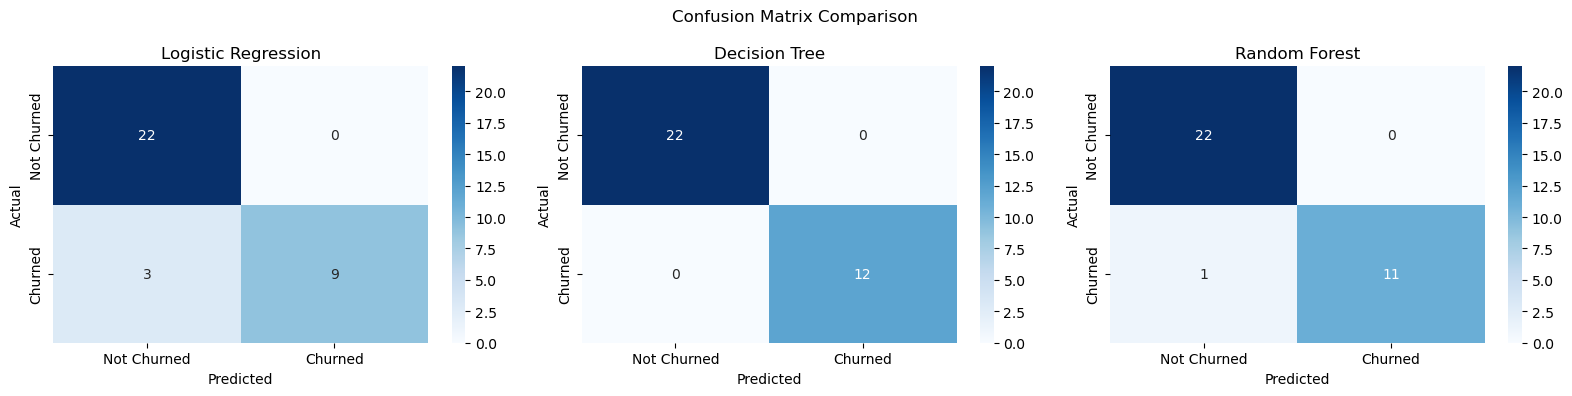

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

predictions_list = [
    ("Logistic Regression", lr_predictions),
    ("Decision Tree", dt_predictions),
    ("Random Forest", rf_predictions)
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(axes, predictions_list):

    actual = [
        row["churn"] for row in predictions.select("churn").collect()
    ]

    predicted = [
        row["prediction"]
        for row in predictions.select("prediction").collect()
    ]

    cm = confusion_matrix(
        actual, predicted, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Churned", "Churned"],
        yticklabels=["Not Churned", "Churned"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

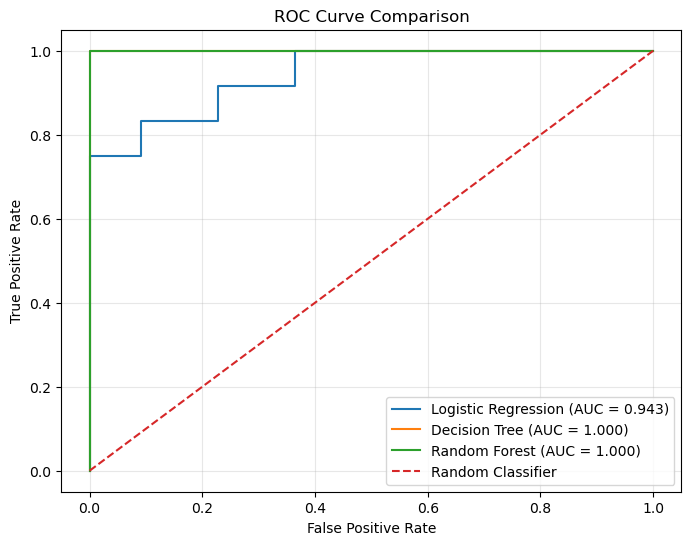

In [43]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

predictions_list = [
    ("Logistic Regression", lr_predictions),
    ("Decision Tree", dt_predictions),
    ("Random Forest", rf_predictions)
]

plt.figure(figsize=(8, 6))

for name, predictions in predictions_list:

    actual = [
        row["churn"]
        for row in predictions.select("churn").collect()
    ]

    probabilities = [
        float(row["probability"][1])
        for row in predictions.select("probability").collect()
    ]

    fpr, tpr, thresholds = roc_curve(actual, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

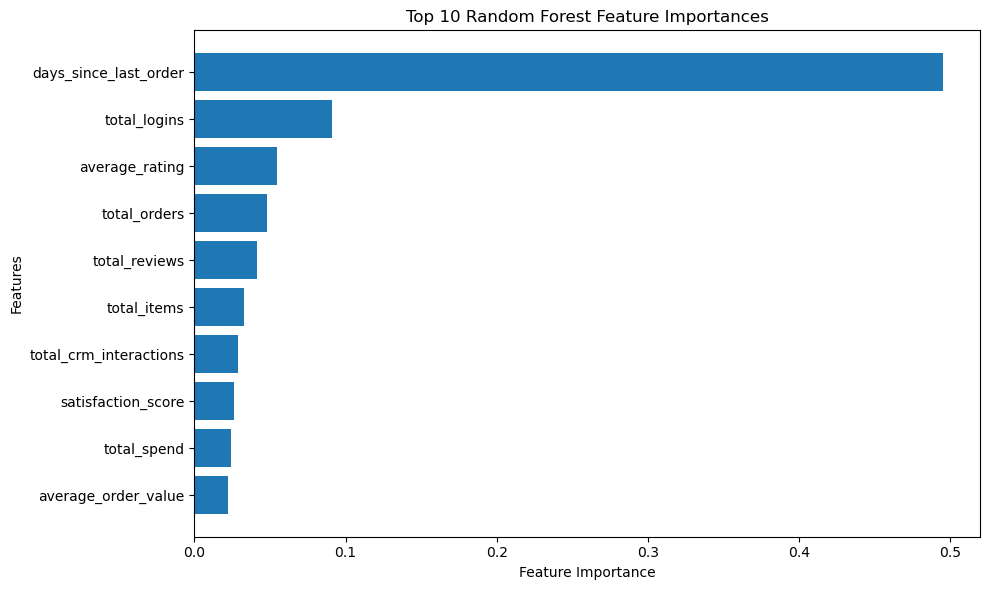

,Feature,Importance
12,days_since_last_order,0.494794
7,total_logins,0.091159
4,average_rating,0.054583
0,total_orders,0.048399
5,total_reviews,0.041233
3,total_items,0.032679
6,total_crm_interactions,0.028867
10,satisfaction_score,0.026442
1,total_spend,0.024081
2,average_order_value,0.022379


In [45]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.featureImportances.toArray()
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Random Forest Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(importance_df)